# Day 39 - Evaluation Classification Model Using ROC, AUC & Confussion Matrix

Membuat model itu mudah; **menilai apakah model benar-benar bagus** adalah keahlian sesungguhnya. Di notebook ini Saya akan fokus pada **cara mengevaluasi model klasifikasi** secara menyeluruh menggunakan: confusion matrix, precision/recall/f1, kurva ROC + AUC, dan kurva Precision-Recall.


Kasus yang dipakai: **prediksi penyakit jantung**.

> 🎯 **Tujuan Pembelajaran**
> - Membaca **confusion matrix** dan menghitung metrik darinya.
> - Memahami **precision, recall, f1-score** lewat `classification_report`.
> - Menggambar & menafsirkan **kurva ROC** beserta **AUC**.
> - Menggambar **kurva Precision-Recall**.
> - Memahami **trade-off** antara menangkap kasus positif vs alarm palsu.

## About Dataset

Dataset **Heart Disease** berisi catatan medis pasien beserta indikasi ada/tidaknya
penyakit jantung.

- **Sumber:** [Kaggle — johnsmith88/heart-disease-dataset](https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset)
- **Jumlah data:** ~1.025 baris × 14 kolom

| Kolom | Arti |
|-------|------|
| `age` | Usia pasien |
| `sex` | Jenis kelamin (1=pria, 0=wanita) |
| `cp` | Tipe nyeri dada |
| `trestbps` | Tekanan darah istirahat |
| `chol` | Kolesterol |
| `thalach` | Detak jantung maksimum |
| `oldpeak` | Depresi ST saat olahraga |
| `target` | **Target**: 1 = ada penyakit jantung, 0 = tidak |

## Import Library


- **pandas / numpy** → olah data.
- **matplotlib / seaborn** → visualisasi.
- **sklearn** → `LogisticRegression`, dan metrik evaluasi: `confusion_matrix`,
  `classification_report`, `roc_curve`, `auc`, `precision_recall_curve`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, precision_recall_curve, average_precision_score

## Import Dataset

In [3]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d johnsmith88/heart-disease-dataset
!unzip heart-disease-dataset.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset
License(s): unknown
100% 6.18k/6.18k [00:00<00:00, 11.2MB/s]

Archive:  heart-disease-dataset.zip
  inflating: heart.csv               


In [8]:
df = pd.read_csv('heart.csv')

## Early Exploration

In [9]:
df.head(3)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [11]:
print(f'Bentuk Dataset: {df.shape}')
print(f'Duplikasi: {df.duplicated().sum()}')
print(f'Missing Value: {df.isna().sum().sum()}')
print(f'Jumlah Kelas Target: {df["target"].value_counts()}')
print(f'Proporsi Kelas Target: {df["target"].value_counts(normalize=True)}')

Bentuk Dataset: (1025, 14)
Duplikasi: 723
Missing Value: 0
Jumlah Kelas Target: target
1    526
0    499
Name: count, dtype: int64
Proporsi Kelas Target: target
1    0.513171
0    0.486829
Name: proportion, dtype: float64


**Interpretasi :**
-  Semua kolom berupa angka (kategori sudah dikodekan sebagai angka), sehingga data langsung bisa dipakai untuk model. Kolom `target` adalah yang ingin kita prediksi.
- Dataset ini mengandung beberapa baris **duplikat**. Untuk evaluasi yang jujur, sebaiknya kita buang duplikat agar baris yang sama tidak bocor ke data latih & uji sekaligus
- Proporsi Kelas Target terlihat seimbang 51:49, sebelum drop duplicate

In [12]:
df = df.drop_duplicates().reset_index(drop=True)

print(f'Bentuk Dataset: {df.shape}')
print(f'Duplikasi: {df.duplicated().sum()}')
print(f'Missing Value: {df.isna().sum().sum()}')
print(f'Jumlah Kelas Target: {df["target"].value_counts()}')
print(f'Proporsi Kelas Target: {df["target"].value_counts(normalize=True)}')

Bentuk Dataset: (302, 14)
Duplikasi: 0
Missing Value: 0
Jumlah Kelas Target: target
1    164
0    138
Name: count, dtype: int64
Proporsi Kelas Target: target
1    0.543046
0    0.456954
Name: proportion, dtype: float64


**Interpretasi**

- Drop Duplicate, menghapus 723 baris, sehingga menyisakan 302 baris dengan 14 kolom
- Proposi kelas masih Seimbang di angka 54.3 : 45.7


## Exploratori Data Analysis and Visualization

### a) Sebaran kelas Target

/tmp/ipykernel_2608/2503252371.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target', data=df, palette="Set2")


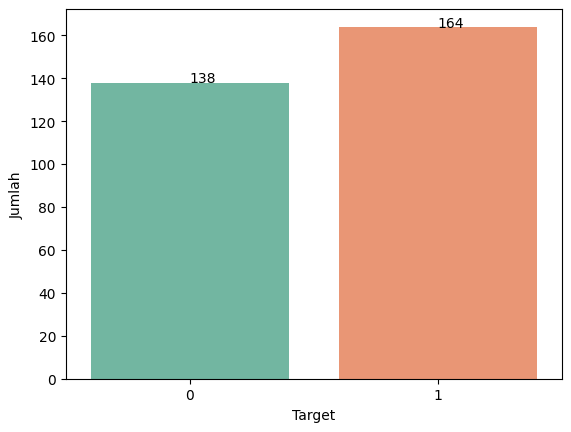

In [14]:
sns.countplot(x='target', data=df, palette="Set2")
plt.xlabel('Target')
plt.ylabel('Jumlah')
for i in range(df['target'].value_counts().shape[0]):
    plt.text(i, df['target'].value_counts()[i], df['target'].value_counts()[i])
plt.show()

**Interpretasi :**
- Kelas Relatif Balanced

### b) Usia vs Detak Jantung Maksimum

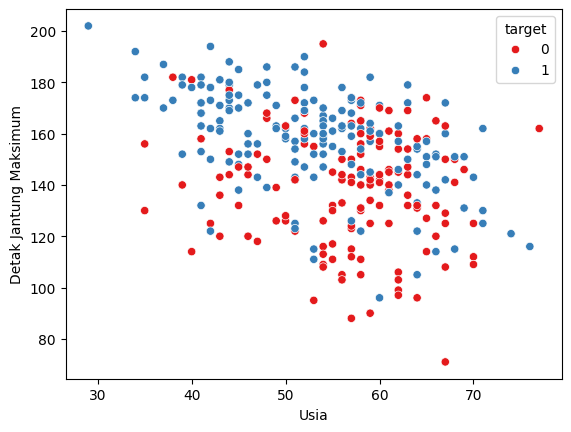

In [16]:
sns.scatterplot(x='age', y='thalach', data=df, hue='target', palette="Set1")
plt.xlabel('Usia')
plt.ylabel('Detak Jantung Maksimum')
plt.show()

**Interpretasi :**
- Pasien dengan penyakit jantung (1) cenderung punya **detak jantung maksimum lebih rendah** pada usia yang sama — pola medis yang masuk akal.

### c) Heatmap Korelasi

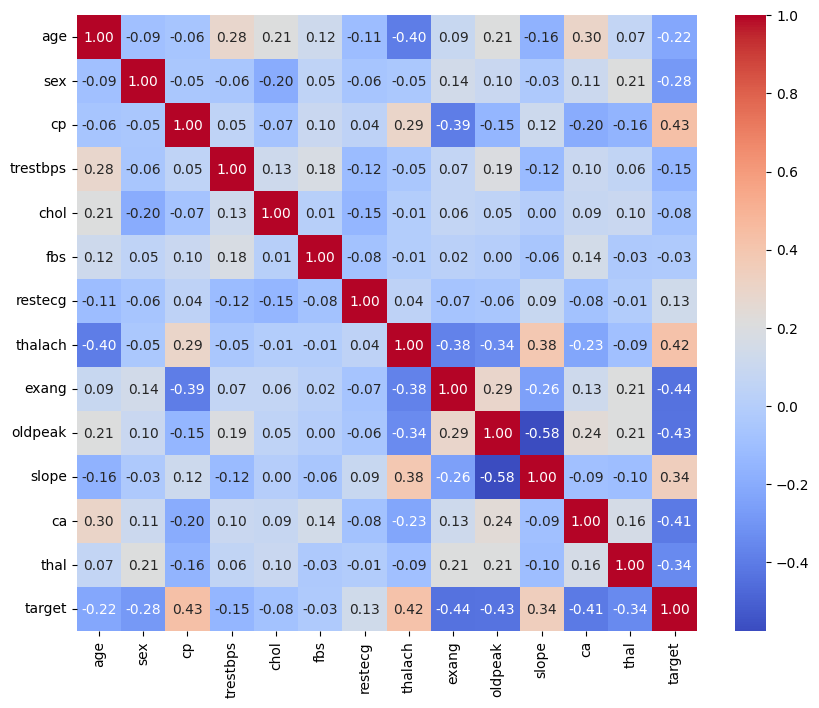

In [17]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm',fmt=".2f")
plt.show()

**Interpretasi :**

Berdasarkan korelasi terkuat dengan target (selain target itu sendiri):

- Lebih mungkin terkena penyakit jantung: Jika pasien memiliki jenis nyeri dada yang parah (cp) dan detak jantung maksimum tinggi (thalach) selama tes stres.

- Kurang mungkin terkena penyakit jantung: Jika pasien mengalami nyeri dada saat berolahraga (exang) atau menunjukkan depresi ST yang signifikan saat berolahraga (oldpeak).

Penting untuk diingat bahwa korelasi adalah langkah pertama dalam analisis dan korelasi individu tidak boleh digunakan sebagai satu-satunya dasar untuk diagnosis. Model multivariat akan memberikan pandangan yang lebih komprehensif

## Preprocessing


Saya split data (stratify agar proporsi kelas terjaga), scaling, lalu latih
**Logistic Regression** — model klasifikasi yang menghasilkan probabilitas, sehingga cocok untuk demonstrasi ROC & threshold.

In [18]:
#Pisahkan fitur dengan target
X = df.drop('target', axis=1)
y = df['target']

In [19]:
#Pisahkan data latih dengan data test
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

In [20]:
#Standarisasi Data latih
scaler = StandardScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

In [21]:
#print
print(f'Bentuk X_train: {X_train.shape}')
print(f'Bentuk y_train: {y_train.shape}')

print(f'Bentuk X_test: {X_test.shape}')
print(f'Bentuk y_test: {y_test.shape}')

Bentuk X_train: (241, 13)
Bentuk y_train: (241,)
Bentuk X_test: (61, 13)
Bentuk y_test: (61,)


**Interpretasi :**

## Modelling

In [22]:
model = LogisticRegression(max_iter=1000,
                           random_state=42)
model.fit(X_train_scale, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [24]:
y_pred = model.predict(X_test_scale)
y_pred_proba = model.predict_proba(X_test_scale)[:,1]

In [25]:
print("Model dilatih. Akurasi uji:", round((y_pred == y_test).mean(), 3))

Model dilatih. Akurasi uji: 0.803


**Interpretasi :**

## Evaluation

### a) Confussion Matrix

Matriks ini memetakan prediksi vs kenyataan ke 4 kotak:
- **TP** (kanan-bawah): sakit & diprediksi sakit ✔
- **TN** (kiri-atas): sehat & diprediksi sehat ✔
- **FP** (kanan-atas): sehat tapi diprediksi sakit (alarm palsu)
- **FN** (kiri-bawah): sakit tapi diprediksi sehat (paling berbahaya secara medis)

In [26]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(cm, columns=['Prediksi 0', 'Prediksi 1'], index=['Aktual 0', 'Aktual 1'])
cm_df

,Prediksi 0,Prediksi 1
Aktual 0,21,7
Aktual 1,5,28


**Interpretasi :**

### b) Classification Report

In [28]:
print(classification_report(y_test, y_pred,
                            target_names=["Sehat", "Sakit"]))

              precision    recall  f1-score   support

       Sehat       0.81      0.75      0.78        28
       Sakit       0.80      0.85      0.82        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.80      0.80      0.80        61



**Interpretasi:**
- **Precision** kelas "Sakit" = dari semua yang diprediksi sakit, berapa yang benar sakit.
- **Recall** kelas "Sakit" = dari semua yang benar-benar sakit, berapa yang berhasil terdeteksi.
- **f1-score** = rata-rata harmonik keduanya. Untuk diagnosis medis, **recall tinggi** sangat penting.

**Interpretasi :**

- Akurasi Model: 80% (model berhasil menebak dengan benar pada 49 dari total 61 data).

- Kelas 0: Model memiliki ketepatan (precision) 81% dan kemampuan deteksi (recall) 75% dari 28 data yang ada.

- Kelas 1: Model memiliki ketepatan (precision) 80% dan kemampuan deteksi (recall) 85% dari 33 data yang ada.

Kesimpulan:
- Performa model sudah cukup baik, seimbang, dan sedikit lebih handal dalam mendeteksi Kelas 1 dibanding Kelas 0.

### c) Kurva ROC vs AUC

Kurva ROC menggambar **True Positive Rate (recall)** vs **False Positive Rate** pada berbagai threshold. **AUC** (Area Under Curve) merangkumnya: 1,0 =  Sempurna, 0,5 = setara tebak koin.

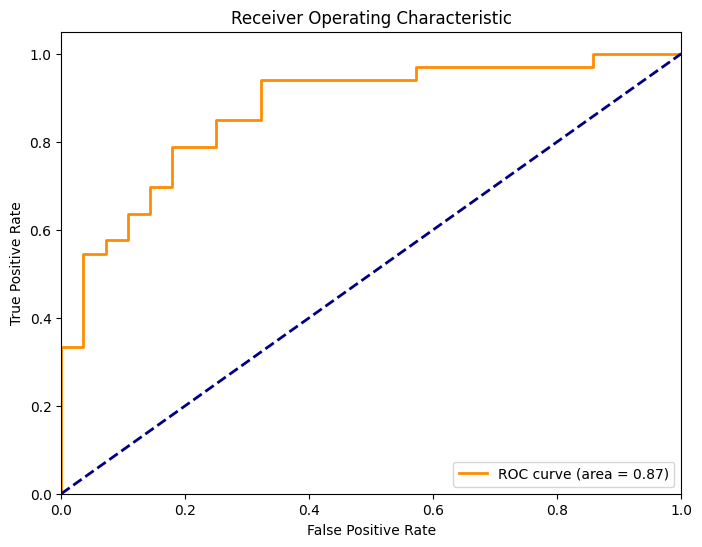

In [30]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)


plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

**Interpretasi :**
 - Nilai AUC (Area Under Curve) = 0.87: Model memiliki performa yang sangat baik dalam membedakan antara kedua kelas (nilai AUC berada di rentang 0,8 - 0,9 dikategorikan sangat baik).

  - Garis Kurva Oranye: Berada jauh di atas garis putus-putus biru (garis tebakan acak), yang menandakan bahwa model memiliki kemampuan prediksi yang jauh lebih baik daripada sekadar menebak secara acak.

### d) Kurva Precission-Recall

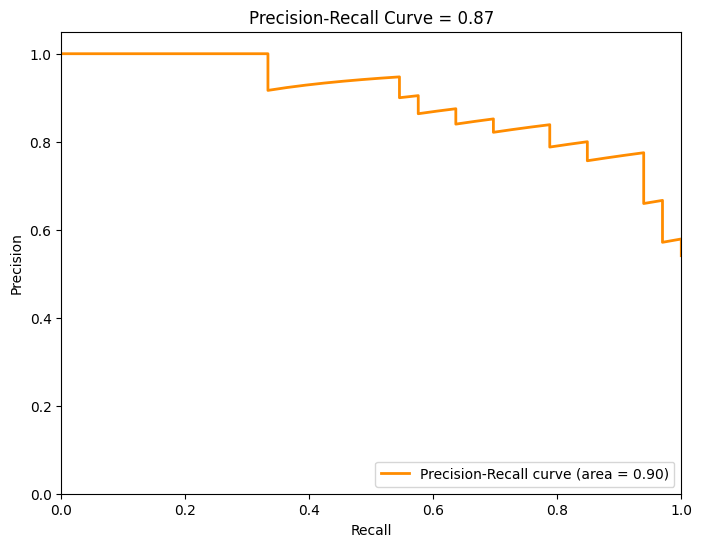

In [32]:
prec, rec, thresholds = precision_recall_curve(y_test, y_pred_proba)
ap = average_precision_score(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(rec, prec, color='darkorange', lw=2, label='Precision-Recall curve (area = %0.2f)' % ap)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve = 0.87')
plt.legend(loc="lower right")
plt.show()

**Interpretasi :**
- Nilai Area / AUC = 0.90: Model menunjukkan performa yang sangat baik dalam menjaga keseimbangan antara tingkat ketepatan (precision) dan kemampuan deteksi (recall).  

- Kestabilan Kurva: Kurva oranye bertahan cukup tinggi (mendekati nilai 1.0) pada tingkat recall rendah hingga menengah, yang menandakan model sangat presisi saat mendeteksi sebagian besar kasus positif sebelum akhirnya sedikit menurun pada recall yang lebih tinggi.

## Kesimpulan & Insight

Berikut adalah beberapa poin kesimpulan dan insight penting dari seluruh proses evaluasi model prediksi penyakit jantung ini:

1. Performa Model Secara Keseluruhan
    * **Akurasi Model mencapai 80.3%** (49 dari 61 pasien di data uji berhasil diprediksi dengan benar). Ini menunjukkan model Logistic Regression bekerja dengan sangat baik sebagai baseline.
   * Nilai **AUC (Area Under Curve) sebesar 0.87** menunjukkan kekuatan diskriminasi model yang sangat tinggi dalam membedakan pasien sehat vs sakit jantung.

2. Analisis Confusion Matrix & Trade-Off Medis
   * **True Positive (TP) = 28** dan **True Negative (TN) = 21** menunjukkan prediksi benar.
   * **False Negative (FN) = 5** (Pasien sakit namun diprediksi sehat). Dalam konteks medis, ini adalah metrik paling krusial karena sangat berbahaya jika ada pasien sakit jantung yang tidak terdeteksi (lolos dari penanganan).

   * **False Positive (FP) = 7** (Pasien sehat diprediksi sakit). Ini mengakibatkan alarm palsu dan pemeriksaan tambahan yang tidak perlu, namun risikonya jauh lebih kecil dibanding FN.


3. Precision vs Recall (Sensitivity)
   * **Recall (Sensitivity) untuk Kelas Sakit (1) mencapai 85%**. Hal ini sangat baik karena model mampu menjaring mayoritas pasien yang benar-benar sakit jantung.
   * **Precision untuk Kelas Sakit (1) berada di angka 80%**, yang berarti dari semua pasien yang dituduh sakit oleh model, 80% di antaranya memang benar-benar sakit.
    * Kurva **Precision-Recall menunjukkan nilai AP (Average Precision) sebesar 0.90**, menandakan stabilitas performa model yang luar biasa baik pada kelas positif meskipun kita mengubah-ubah threshold keputusannya.

4. Rekomendasi Selanjutnya (Actionable Insights)
    * **Penyesuaian Threshold:** Karena ini adalah kasus medis, kita bisa menurunkan threshold probabilitas (default: 0.5) menjadi misalnya 0.4 atau 0.3 untuk menekan nilai **False Negative (FN)** mendekati 0, meskipun konsekuensinya kita akan mendapatkan lebih banyak False Positive (FP).
   * **Analisis Fitur:** Berdasarkan visualisasi EDA sebelumnya, fitur seperti jenis nyeri dada (`cp`) dan detak jantung maksimum (`thalach`) memiliki korelasi yang sangat kuat dengan target positif, sehingga patut diperhatikan